# Multi-household baseline comparison

No-PV baseline against PV scenarios for several households, with separate and group
invoice views. No optimization and no VPP control: interval pricing under the SI
dynamic package, plus a souporaba monthly settlement summary.

In [1]:
import pandas as pd

import Anonymous_Labels as anon
from Data_Loader import load_multiple_households
from multi_household_tools import (
    run_interval_scenario,
    run_souporaba_monthly_scenario,
)

### Shared chart styling
import importlib
import Plotting_Functions as pf   # one module decides style, size and export

# Reloaded like the other repo modules: `import` returns whatever the kernel
# cached the first time, so editing Plotting_Functions and re-running this cell
# would otherwise keep the old module -- which shows up as a TypeError about an
# argument that does exist in the file.
pf = importlib.reload(pf)

# titles=False: an IEEE figure carries no title of its own -- the caption below
# it, set in the article, is the title. The text is not lost, it goes into each
# export's SOURCE.md as the caption to use.
pf.use(subdir="multi_household_baseline", titles=False)
from Plotting_Functions import SERIES, EUR, finish


In [2]:
# Select a small household group for baseline comparison.
HOUSEHOLD_IDS = [29, 30, 31]
HOUSEHOLD_DATA = {str(k): v for k, v in load_multiple_households(HOUSEHOLD_IDS).items()}

print(f"Loaded households: {list(HOUSEHOLD_DATA.keys())}")
for hid, df in HOUSEHOLD_DATA.items():
    print(f"{hid}: rows={len(df)} from {df.index.min()} to {df.index.max()}")

Loaded households: ['29', '30', '31']
29: rows=52608 from 2010-07-01 00:30:00+00:00 to 2013-07-01 00:00:00+00:00
30: rows=52608 from 2010-07-01 00:30:00+00:00 to 2013-07-01 00:00:00+00:00
31: rows=52608 from 2010-07-01 00:30:00+00:00 to 2013-07-01 00:00:00+00:00


In [3]:
# Scenario 1: no PV baseline under the SI dynamic package. `paket_id` is the
# catalogue KEY the pricing library is asked for; `scenario_name` is a LABEL that
# reaches every table below, so it carries the anonymous name instead.
baseline_no_pv = run_interval_scenario(
    HOUSEHOLD_DATA,
    scenario_name="Ponudnik 3 Dinamični, brez PV",
    scheme="si_dobava",
    paket_id="GENI_DINAMICNI",
    pv_scale_map={hid: 0.0 for hid in HOUSEHOLD_DATA.keys()},
)

# Scenario 2: PV enabled under the SI samooskrba dynamic package.
pv_enabled = run_interval_scenario(
    HOUSEHOLD_DATA,
    scenario_name="Ponudnik 3 Samo Dinamični, s PV",
    scheme="si_samooskrba",
    paket_id="GENI_SAMO_DINAMICNI",
    pv_scale_map={hid: 1.0 for hid in HOUSEHOLD_DATA.keys()},
)

In [4]:
summary_compare = pd.concat([baseline_no_pv["summary"], pv_enabled["summary"]], ignore_index=True)
# `paket_id` is the catalogue key: fine in the frame, not in a rendered table.
display(anon.scrub_frame(summary_compare).drop(columns=["paket_id"], errors="ignore"))

group_only = summary_compare[summary_compare["household_id"] == "GROUP"].copy()
display(group_only[["scenario", "total_cost_eur", "total_imported_kwh", "total_exported_kwh"]])

,scenario,household_id,interval_minutes,pv_scale,scheme,contracted_power_kw,total_consumption_kwh,total_generation_kwh,total_imported_kwh,total_exported_kwh,peak_import_kw,energy_eur,power_eur,fixed_eur,credit_eur,total_cost_eur
0,"Ponudnik 3 Dinamični, brez PV",29,30.0,0.0,si_dobava,5.0,13461.622,0.000,13461.622,0.000,5.242,970.506744,0.277553,676.622737,0.000000,1647.407034
1,"Ponudnik 3 Dinamični, brez PV",30,30.0,0.0,si_dobava,5.0,7227.320,0.000,7227.320,0.000,4.070,516.546590,0.000000,676.622737,0.000000,1193.169327
2,"Ponudnik 3 Dinamični, brez PV",31,30.0,0.0,si_dobava,5.0,17837.636,0.000,17837.636,0.000,9.016,1234.268685,11.285893,676.622737,0.000000,1922.177315
3,"Ponudnik 3 Dinamični, brez PV",GROUP,None,None,NaN,15.0,38526.578,0.000,38526.578,0.000,13.434,2721.322020,11.563447,2029.868210,0.000000,4762.753676
4,"Ponudnik 3 Samo Dinamični, s PV",29,30.0,1.0,si_samooskrba,5.0,13461.622,6027.260,10574.570,3140.208,5.242,722.791133,0.277553,676.622737,37.782306,1399.691423
5,"Ponudnik 3 Samo Dinamični, s PV",30,30.0,1.0,si_samooskrba,5.0,7227.320,4289.452,5562.613,2624.745,4.070,365.884581,0.000000,676.622737,32.184026,1042.507317
6,"Ponudnik 3 Samo Dinamični, s PV",31,30.0,1.0,si_samooskrba,5.0,17837.636,5802.453,14234.281,2199.098,9.016,952.344834,9.173863,676.622737,31.155119,1638.141434
7,"Ponudnik 3 Samo Dinamični, s PV",GROUP,None,None,NaN,15.0,38526.578,16119.165,30371.464,7964.051,13.010,2041.020548,9.451416,2029.868210,101.121451,4080.340174


,scenario,total_cost_eur,total_imported_kwh,total_exported_kwh
3,"Ponudnik 3 Dinamični, brez PV",4762.753676,38526.578,0.000
7,"Ponudnik 3 Samo Dinamični, s PV",4080.340174,30371.464,7964.051


In [5]:
# Separate and group invoice line-item views from interval scenarios.
baseline_invoices = baseline_no_pv["invoice_views"]
pv_invoices = pv_enabled["invoice_views"]

# `si_obracun` writes the package as "<dobavitelj> - <ime>", so the invoice rows
# are scrubbed on the way to the screen. The invoice generator notebook does NOT
# do this: an invoice has to name the contract it was issued under.
print("Baseline GROUP invoice rows:")
display(anon.scrub_frame(pd.DataFrame(baseline_invoices["group"])).head(20))

print("PV GROUP invoice rows:")
display(anon.scrub_frame(pd.DataFrame(pv_invoices["group"])).head(20))

first_hh = list(HOUSEHOLD_DATA.keys())[0]
print(f"Baseline separate invoice rows for household {first_hh}:")
display(anon.scrub_frame(
    pd.DataFrame(baseline_invoices["separate"][first_hh])).head(20))

Baseline GROUP invoice rows:


,obdobje,produkt,kolicina,enota,cena_eur_em,znesek_eur_brez_ddv,kategorija
0,Skupno_obdobje,Skupni obračun gospodinjstev,NaN,NaN,NaN,NaN,naslov
1,Skupno_obdobje,Električna energija – blok 2,11795.642,kWh,0.037367,440.76467,energija
2,Skupno_obdobje,Električna energija – blok 3,11519.408,kWh,0.037071,427.03654,energija
3,Skupno_obdobje,Električna energija – blok 4,9220.207,kWh,0.035688,329.05412,energija
4,Skupno_obdobje,Električna energija – blok 5,2645.712,kWh,0.035266,93.30483,energija
5,Skupno_obdobje,Skupaj električna energija,NaN,NaN,NaN,1427.38664,skupaj
6,Skupno_obdobje,Dogovorjena moč za časovni blok 2,555.000,kW,1.092300,606.22650,omreznina
7,Skupno_obdobje,Dogovorjena moč za časovni blok 3,555.000,kW,0.289020,160.40610,omreznina
8,Skupno_obdobje,Dogovorjena moč za časovni blok 4,555.000,kW,0.024360,13.51980,omreznina
9,Skupno_obdobje,Dogovorjena moč za časovni blok 5,375.000,kW,0.002450,0.91875,omreznina


PV GROUP invoice rows:


,obdobje,produkt,kolicina,enota,cena_eur_em,znesek_eur_brez_ddv,kategorija
0,Skupno_obdobje,Skupni obračun gospodinjstev,NaN,NaN,NaN,NaN,naslov
1,Skupno_obdobje,Električna energija – blok 2,8062.905,kWh,0.037643,303.51191,energija
2,Skupno_obdobje,Električna energija – blok 3,9251.671,kWh,0.037501,346.95100,energija
3,Skupno_obdobje,Električna energija – blok 4,8788.524,kWh,0.035771,314.37170,energija
4,Skupno_obdobje,Električna energija – blok 5,2645.193,kWh,0.035266,93.28669,energija
5,Skupno_obdobje,Skupaj električna energija,NaN,NaN,NaN,1132.21266,skupaj
6,Skupno_obdobje,Dogovorjena moč za časovni blok 2,555.000,kW,1.092300,606.22650,omreznina
7,Skupno_obdobje,Dogovorjena moč za časovni blok 3,555.000,kW,0.289020,160.40610,omreznina
8,Skupno_obdobje,Dogovorjena moč za časovni blok 4,555.000,kW,0.024360,13.51980,omreznina
9,Skupno_obdobje,Dogovorjena moč za časovni blok 5,375.000,kW,0.002450,0.91875,omreznina


Baseline separate invoice rows for household 29:


,obdobje,produkt,kolicina,enota,cena_eur_em,znesek_eur_brez_ddv,kategorija
0,Skupno_obdobje,Ponudnik 3 Dinamični,NaN,NaN,NaN,NaN,naslov
1,Skupno_obdobje,Električna energija – blok 2,4421.558,kWh,0.038245,169.10131,energija
2,Skupno_obdobje,Električna energija – blok 3,4119.718,kWh,0.038156,157.19085,energija
3,Skupno_obdobje,Električna energija – blok 4,2817.892,kWh,0.036729,103.49838,energija
4,Skupno_obdobje,Električna energija – blok 5,764.138,kWh,0.036332,27.76284,energija
5,Skupno_obdobje,Skupaj električna energija,NaN,NaN,NaN,512.84390,skupaj
6,Skupno_obdobje,Dogovorjena moč za časovni blok 2,185.000,kW,1.092300,202.07550,omreznina
7,Skupno_obdobje,Dogovorjena moč za časovni blok 3,185.000,kW,0.289020,53.46870,omreznina
8,Skupno_obdobje,Dogovorjena moč za časovni blok 4,185.000,kW,0.024360,4.50660,omreznina
9,Skupno_obdobje,Dogovorjena moč za časovni blok 5,125.000,kW,0.002450,0.30625,omreznina


In [6]:
# Souporaba monthly settlement summary:
# - first household is oddajnik
# - remaining households are prejemniki
oddajnik_id = list(HOUSEHOLD_DATA.keys())[0]
prejemnik_ids = list(HOUSEHOLD_DATA.keys())[1:]

souporaba_df = run_souporaba_monthly_scenario(
    HOUSEHOLD_DATA,
    scenario_name="Ponudnik 3 souporaba, dinamični",
    oddajnik_id=oddajnik_id,
    prejemnik_ids=prejemnik_ids,
    pv_scale_map={hid: (1.0 if hid == oddajnik_id else 0.0) for hid in HOUSEHOLD_DATA.keys()},
    organizer_service_id="GENI_SOUPORABA",
    oddajnik_paket_id="GENI_SAMO_DINAMICNI",
    prejemnik_paket_id="GENI_DINAMICNI",
)

display(anon.scrub_frame(souporaba_df))

,scenario,household_id,za_placilo_eur,neto_eur,ddv_eur,bruto_eur,prevzeto_kwh,oddano_kwh,deljeno_kwh
0,"Ponudnik 3 souporaba, dinamični",29,48.740643,40.147970,8.832553,48.980524,466.932,6.28,4.19
1,"Ponudnik 3 souporaba, dinamični",30,39.861250,32.673156,7.188094,39.861250,402.043,0.00,2.06
2,"Ponudnik 3 souporaba, dinamični",31,75.305709,61.725991,13.579718,75.305709,935.498,0.00,2.09
3,"Ponudnik 3 souporaba, dinamični",GROUP,163.907601,NaN,NaN,NaN,NaN,NaN,NaN


findfont: Failed to find font weight semibold, now using 700.


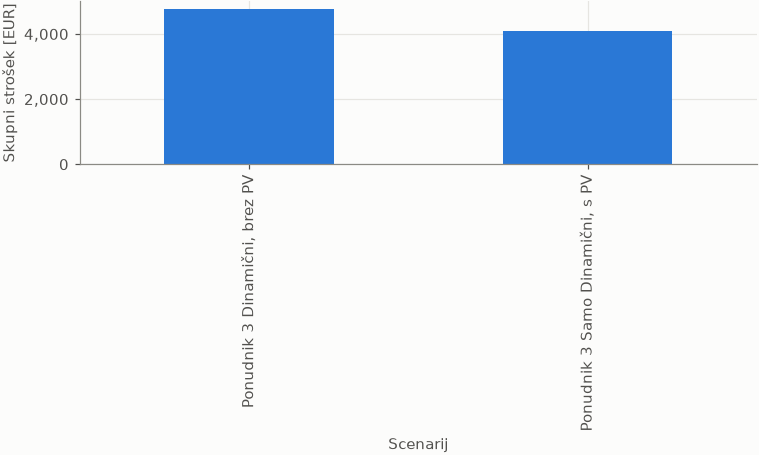

In [7]:
# Quick visual for group total comparison.
group_plot_df = group_only[["scenario", "total_cost_eur"]].copy()
ax = group_plot_df.plot(kind="bar", x="scenario", y="total_cost_eur",
                        legend=False, color=SERIES[0])
finish(ax, title="Primerjava skupnega stroška skupine",
       xlabel="Scenarij", ylabel="Skupni strošek [EUR]", yfmt=EUR)
pf.show(ax, "group_total_cost")